# Single-Stock Risk Report

A parameterized report for one ticker over one date range. It reads the cleaned table `ohlc_hw_cleaned` produced by `01_data_cleaning.ipynb`.

* Returns, volatility, Sharpe, and the daily-return statistics use **daily log returns of the adjusted close**.
* Drawdown uses the adjusted close.
* Values are fractions in all calculations and in saved outputs. Percent formatting is applied only for display.

Run it directly, or through papermill (`03_run_all_stocks.py`), which overrides the tagged `parameters` cell below.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working copy of the course database
risk_free_rate = 0.02  # Annual risk-free rate used in the Sharpe ratio
volatility_window = 20  # Rolling window (trading days) for volatility
ma_window = 50  # Moving-average window (trading days) for the price chart

In [3]:
# Parameters
ticker = "MRK"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/guillaumeestepa/Documents/Education/QUANT/Berkeley MFE/Classes/Pre-requisites/MFE - Python for Financial Engineers/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Guillaume_Estepa/data/data.db"


## Data loading

In [4]:
TRADING_DAYS = 252
CLEAN_TABLE = 'ohlc_hw_cleaned'

# Validate the parameters before touching the database.
database = Path(db_path).expanduser().resolve()
if not database.is_file():
    raise FileNotFoundError(f'Database not found at {database}; run 01_data_cleaning.ipynb first.')
start_ts, end_ts = pd.Timestamp(start_date), pd.Timestamp(end_date)
if start_ts > end_ts:
    raise ValueError(f'start_date {start_date} is after end_date {end_date}.')
for name, value in {'volatility_window': volatility_window, 'ma_window': ma_window}.items():
    if not isinstance(value, int) or isinstance(value, bool) or value < 2:
        raise ValueError(f'{name} must be an integer >= 2, got {value!r}.')
ticker = str(ticker).strip().upper()

query = f'''
SELECT ts, open, high, low, close, adj_close, volume
FROM {CLEAN_TABLE}
WHERE ticker = ? AND ts >= ? AND ts <= ?
ORDER BY ts
'''
with closing(sqlite3.connect(database.as_uri() + '?mode=ro', uri=True)) as conn:
    df = pd.read_sql_query(query, conn, params=(ticker, start_ts.strftime('%Y-%m-%d'), end_ts.strftime('%Y-%m-%d')),
                           parse_dates=['ts'], index_col='ts')

# Input checks: the report needs at least volatility_window returns, i.e. volatility_window + 1 prices.
min_prices = volatility_window + 1
if df.empty:
    raise ValueError(f'{ticker}: no rows in {CLEAN_TABLE} between {start_date} and {end_date}.')
if len(df) < min_prices:
    raise ValueError(f'{ticker}: insufficient history. {volatility_window} returns need at least {min_prices} prices, '
                     f'got {len(df)} ({df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}).')
if df.index.duplicated().any() or not df.index.is_monotonic_increasing:
    raise ValueError(f'{ticker}: dates must be unique and sorted.')
if not (np.isfinite(df['adj_close']).all() and (df['adj_close'] > 0).all()):
    raise ValueError(f'{ticker}: adjusted close must be finite and positive.')

first_obs, last_obs = df.index.min(), df.index.max()
print(f'{ticker} from {start_date} to {end_date}: {len(df)} trading days')
print(f'Actual coverage: first observation {first_obs:%Y-%m-%d}, last observation {last_obs:%Y-%m-%d}')
if last_obs < end_ts - pd.Timedelta(days=7):
    print(f'NOTE: the supplied history for {ticker} ends on {last_obs:%Y-%m-%d}, before the requested end date. '
          'Metrics cover the available data only; nothing is extrapolated.')
display(df.head())
display(df.tail())

MRK from 2024-06-01 to 2024-11-30: 126 trading days
Actual coverage: first observation 2024-06-03, last observation 2024-11-29


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,125.77,128.95,125.77,128.42,126.81,7702676.0
2024-06-04,127.15,129.36,126.88,128.71,127.09,6440167.0
2024-06-05,128.48,129.94,128.07,129.45,127.82,5009502.0
2024-06-06,129.16,130.93,128.90,130.52,128.88,8088641.0
2024-06-07,130.35,131.37,130.21,130.67,129.03,4945600.0


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-22,100.33,101.79,98.93,99.18,99.18,14031200.0
2024-11-25,100.09,101.74,99.51,101.16,101.16,34659100.0
2024-11-26,101.48,101.80,99.70,101.62,101.62,9324100.0
2024-11-27,101.65,103.45,101.64,103.12,103.12,9802200.0
2024-11-29,102.88,103.04,101.53,101.64,101.64,6081200.0


## Risk metric functions

In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    '''Calculate daily log returns.

    Parameters
    ----------
    prices : pd.Series
        Sorted, positive prices (here: adjusted close).

    Returns
    -------
    pd.Series
        log(P_t / P_{t-1}); the first value is NaN (no previous price).
    '''
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    '''Calculate annualized rolling volatility.

    Sample standard deviation (ddof=1) of daily log returns over a full window,
    scaled by sqrt(252). The warm-up period stays NaN: an estimate needs `window` returns.
    '''
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    '''Return per-date drawdown from the running price peak.

    drawdown_t = (P_t - max_{s<=t} P_s) / max_{s<=t} P_s, always <= 0.
    The series can recover; the maximum drawdown is drawdown.min().
    '''
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    '''Calculate annualized Sharpe ratio (course approximation).

    (mean_daily_return * 252 - rf) / (std_daily_return * sqrt(252)).
    Returns NaN when it is undefined: fewer than 2 returns or zero/non-finite volatility.
    '''
    observed = returns.dropna()
    if len(observed) < 2:
        return np.nan
    sigma = observed.std()
    if not np.isfinite(sigma) or np.isclose(sigma, 0.0):
        return np.nan
    return (observed.mean() * TRADING_DAYS - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS))


# Quick self-checks on tiny inputs, so a broken function fails loudly.
_p = pd.Series([100.0, 110.0, 99.0, 120.0])
assert np.isclose(calculate_returns(_p).iloc[1], np.log(1.1))
assert np.allclose(calculate_max_drawdown(_p).values, [0.0, 0.0, -0.1, 0.0])
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01])))
assert calculate_volatility(calculate_returns(_p), window=2).iloc[:2].isna().all()

In [6]:
prices = df['adj_close']
df['log_return'] = calculate_returns(prices)
df['volatility'] = calculate_volatility(df['log_return'], window=volatility_window)
df['drawdown'] = calculate_max_drawdown(prices)
df[f'ma_{ma_window}'] = prices.rolling(ma_window).mean()   # NaN until ma_window prices exist

log_returns = df['log_return'].dropna()
sharpe_ratio = calculate_sharpe_ratio(log_returns, risk_free_rate)
mean_rolling_vol = df['volatility'].mean()   # NaN-aware mean over the available estimates
max_drawdown = df['drawdown'].min()
max_dd_date = df['drawdown'].idxmin()

display(df[['adj_close', 'log_return', 'volatility', 'drawdown', f'ma_{ma_window}']].iloc[volatility_window - 2:volatility_window + 3])
print(f'Sharpe ratio: {sharpe_ratio:.3f}' if np.isfinite(sharpe_ratio) else 'Sharpe ratio: N/A')
print(f'Mean {volatility_window}-day rolling volatility: {mean_rolling_vol:.2%}')
print(f'Maximum drawdown: {max_drawdown:.2%} on {max_dd_date:%Y-%m-%d}')

,adj_close,log_return,volatility,drawdown,ma_50
ts,,,,,
2024-06-28,122.98,-0.047481,NaN,-0.068898,NaN
2024-07-01,127.05,0.032559,NaN,-0.038083,NaN
2024-07-02,126.87,-0.001418,0.246352,-0.039446,NaN
2024-07-03,125.01,-0.014769,0.251669,-0.053528,NaN
2024-07-05,125.61,0.004788,0.251367,-0.048985,NaN


Sharpe ratio: -1.934
Mean 20-day rolling volatility: 23.27%
Maximum drawdown: -27.08% on 2024-11-15


## Visualization

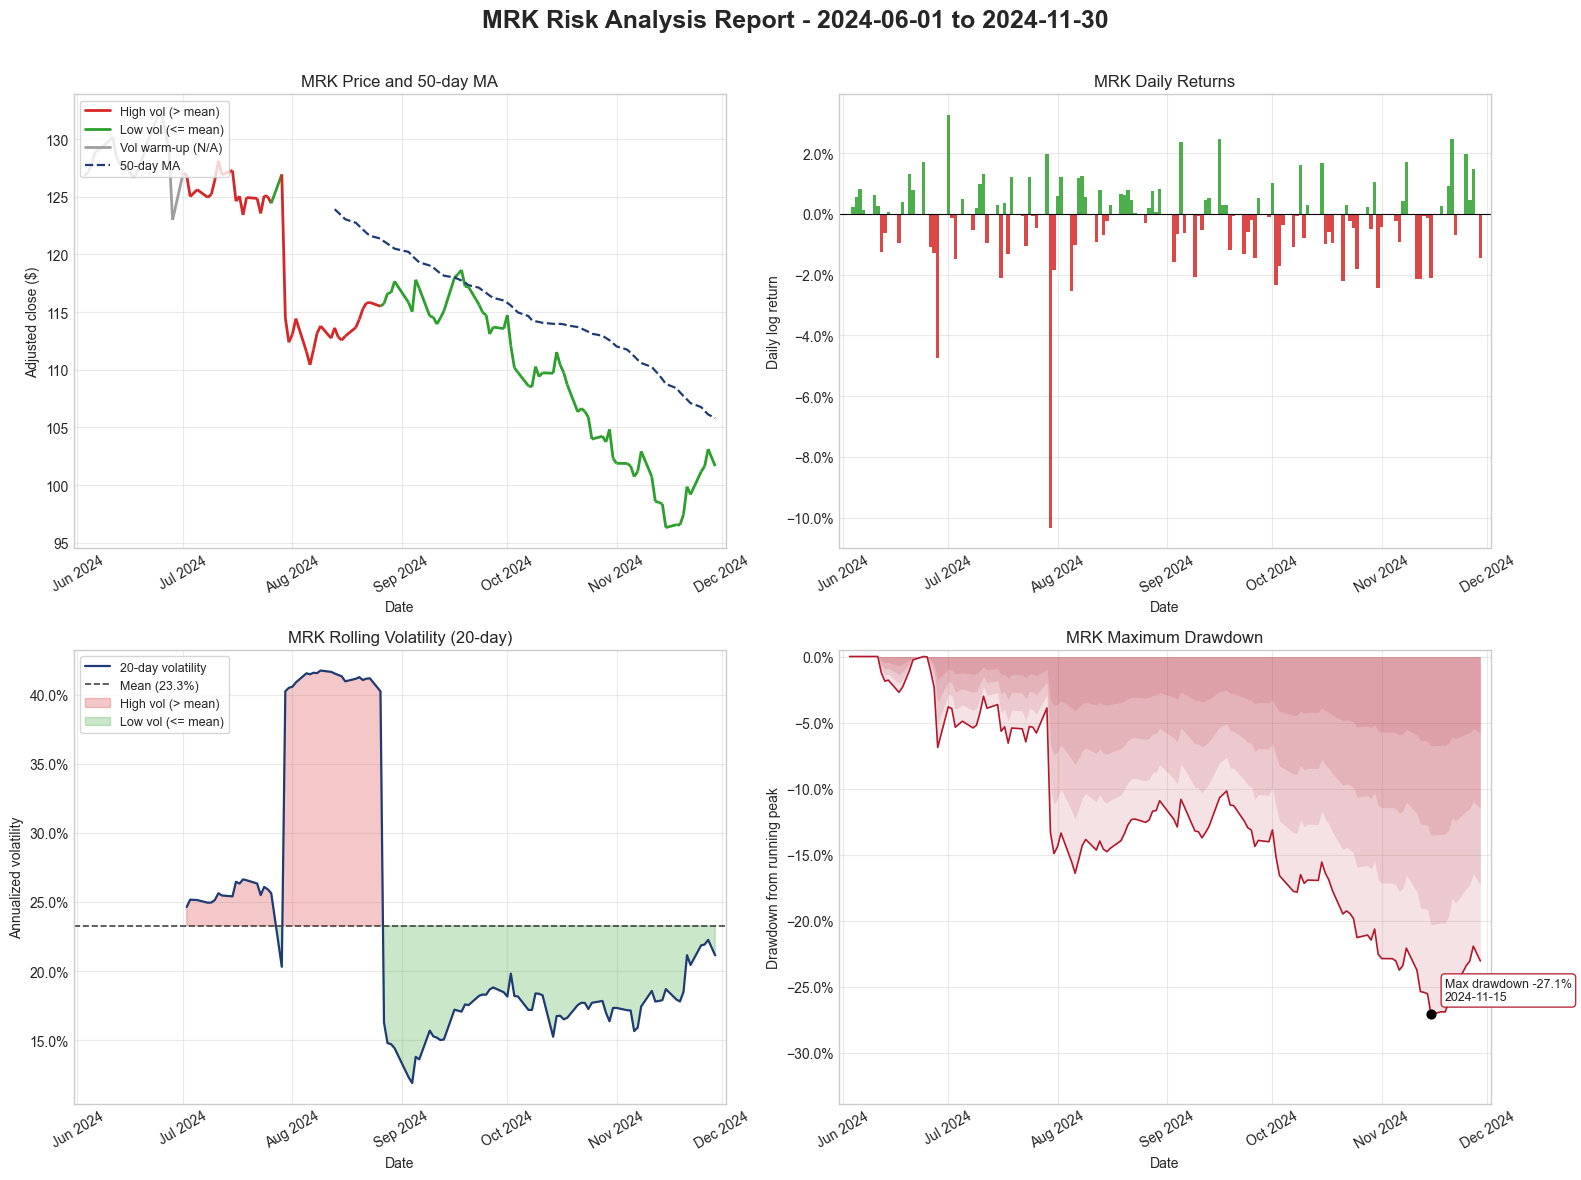

In [7]:
COLORS = {'high': '#d62728', 'low': '#2ca02c', 'na': '#9e9e9e', 'ma': '#1f3b73', 'mean': '#444444', 'dd': '#b2182b'}


def plot_price_by_volatility(ax, prices: pd.Series, vol: pd.Series, ma: pd.Series, threshold: float):
    # Price line whose segments are colored by that day's rolling volatility vs. the threshold.
    x = mdates.date2num(prices.index.to_pydatetime())
    points = np.column_stack([x, prices.values])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    seg_vol = vol.values[1:]   # segment i ends on day i+1
    colors = np.where(np.isnan(seg_vol), COLORS['na'], np.where(seg_vol > threshold, COLORS['high'], COLORS['low']))
    ax.add_collection(LineCollection(segments, colors=colors, linewidths=2))
    ax.autoscale_view()
    handles = [Line2D([], [], color=COLORS['high'], lw=2, label='High vol (> mean)'),
               Line2D([], [], color=COLORS['low'], lw=2, label='Low vol (<= mean)'),
               Line2D([], [], color=COLORS['na'], lw=2, label='Vol warm-up (N/A)')]
    if ma.notna().any():
        ax.plot(ma.index, ma, color=COLORS['ma'], lw=1.6, ls='--', label=f'{ma_window}-day MA')
        handles.append(Line2D([], [], color=COLORS['ma'], lw=1.6, ls='--', label=f'{ma_window}-day MA'))
    else:
        ax.text(0.02, 0.04, f'{ma_window}-day MA unavailable: only {len(prices)} prices in range',
                transform=ax.transAxes, fontsize=9, color=COLORS['mean'])
    ax.legend(handles=handles, loc='upper left', fontsize=9, frameon=True)


fig, axes = plt.subplots(2, 2, figsize=(16, 12))
(ax_price, ax_ret), (ax_vol, ax_dd) = axes
vol_threshold = mean_rolling_vol

# Top left: price and moving average, colored by volatility regime.
plot_price_by_volatility(ax_price, prices, df['volatility'], df[f'ma_{ma_window}'], vol_threshold)
ax_price.set(title=f'{ticker} Price and {ma_window}-day MA', ylabel='Adjusted close ($)')

# Top right: daily log returns.
bar_colors = np.where(df['log_return'] >= 0, COLORS['low'], COLORS['high'])
ax_ret.bar(df.index, df['log_return'].fillna(0), color=bar_colors, width=1.0, alpha=0.85)
ax_ret.axhline(0, color='black', lw=0.8)
ax_ret.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_ret.set(title=f'{ticker} Daily Returns', ylabel='Daily log return')

# Bottom left: rolling volatility with regime shading around its mean.
vol = df['volatility']
ax_vol.plot(vol.index, vol, color=COLORS['ma'], lw=1.6, label=f'{volatility_window}-day volatility')
if np.isfinite(vol_threshold):
    ax_vol.axhline(vol_threshold, color=COLORS['mean'], ls='--', lw=1.2, label=f'Mean ({vol_threshold:.1%})')
    ax_vol.fill_between(vol.index, vol_threshold, vol, where=vol > vol_threshold, color=COLORS['high'], alpha=0.25,
                        interpolate=True, label='High vol (> mean)')
    ax_vol.fill_between(vol.index, vol_threshold, vol, where=vol <= vol_threshold, color=COLORS['low'], alpha=0.25,
                        interpolate=True, label='Low vol (<= mean)')
ax_vol.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_vol.set(title=f'{ticker} Rolling Volatility ({volatility_window}-day)', ylabel='Annualized volatility')
ax_vol.legend(loc='upper left', fontsize=9, frameon=True)

# Bottom right: drawdown area with a layered red gradient and the worst point marked.
dd = df['drawdown']
for frac, alpha in [(1.0, 0.12), (0.75, 0.12), (0.5, 0.12), (0.25, 0.12)]:
    ax_dd.fill_between(dd.index, 0, dd * frac, color=COLORS['dd'], alpha=alpha, lw=0)
ax_dd.plot(dd.index, dd, color=COLORS['dd'], lw=1.2)
ax_dd.scatter([max_dd_date], [max_drawdown], color='black', zorder=5, s=40)
ax_dd.annotate(f'Max drawdown {max_drawdown:.1%}\n{max_dd_date:%Y-%m-%d}', (max_dd_date, max_drawdown),
               xytext=(10, 10), textcoords='offset points', fontsize=9,
               bbox=dict(boxstyle='round', fc='white', ec=COLORS['dd'], alpha=0.9))
ax_dd.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_dd.set(title=f'{ticker} Maximum Drawdown', ylabel='Drawdown from running peak')
ax_dd.set_ylim(min(max_drawdown * 1.25, -0.01), 0.005)

for ax in axes.flat:
    ax.grid(True, alpha=0.4)
    ax.set_xlabel('Date')
    ax.set_xlim(first_obs - pd.Timedelta(days=3), last_obs + pd.Timedelta(days=3))   # same date axis on every panel
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.tick_params(axis='x', rotation=30)
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=18, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

**Reading the chart.** Price colors are *retrospective*. The threshold is the mean rolling volatility over this whole report, so they describe the period after the fact and are not a real-time signal. Gray segments are the first days where the 20-day volatility does not exist yet. Warm-up gaps are kept as gaps (never filled with zero).

## Summary statistics

In [8]:
def summarize_performance(prices: pd.Series, log_returns: pd.Series, drawdown: pd.Series,
                          risk_free_rate: float = 0.02) -> dict:
    '''Whole-period summary metrics as fractions (NaN where undefined).'''
    r = log_returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    return {
        'Total Return': prices.iloc[-1] / prices.iloc[0] - 1,
        'Annualized Return': np.expm1(r.sum() * TRADING_DAYS / n) if n else np.nan,
        'Annualized Volatility': r.std() * np.sqrt(TRADING_DAYS) if n > 1 else np.nan,
        'Sharpe Ratio': calculate_sharpe_ratio(r, risk_free_rate),
        'Maximum Drawdown': drawdown.min(),
        'Best Day': r.max() if n else np.nan,
        'Worst Day': r.min() if n else np.nan,
        'Positive Days': len(up) / n if n else np.nan,   # zero-return days count in the denominator
        'Average Up Day': up.mean() if len(up) else np.nan,
        'Average Down Day': down.mean() if len(down) else np.nan,
    }


def format_metric(name: str, value: float) -> str:
    # Display formatting only; the underlying values stay as fractions.
    if not np.isfinite(value):
        return 'N/A'
    if name == 'Sharpe Ratio':
        return f'{value:.2f}'
    if name in ('Annualized Volatility', 'Positive Days'):
        return f'{value:.1%}'
    return f'{value:+.2%}'


summary = summarize_performance(prices, df['log_return'], df['drawdown'], risk_free_rate)
summary_table = pd.DataFrame({'Metric': list(summary), 'Value': [format_metric(k, v) for k, v in summary.items()]})
print(f'{ticker}: {first_obs:%Y-%m-%d} to {last_obs:%Y-%m-%d}, {len(df)} prices, {len(log_returns)} daily log returns')
print(f"{'Metric':<24}  {'Value':>8}\n{'-' * 24}  {'-' * 8}")
for _, row in summary_table.iterrows():
    print(f"{row['Metric']:<24}  {row['Value']:>8}")

# Consistency checks between the different ways of computing the same quantity.
assert np.isclose(np.expm1(log_returns.sum()), summary['Total Return'])
assert np.isclose(summary['Sharpe Ratio'], sharpe_ratio, equal_nan=True)

MRK: 2024-06-03 to 2024-11-29, 126 prices, 125 daily log returns
Metric                       Value
------------------------  --------
Total Return               -19.85%
Annualized Return          -35.98%
Annualized Volatility        24.1%
Sharpe Ratio                 -1.93
Maximum Drawdown           -27.08%
Best Day                    +3.26%
Worst Day                  -10.32%
Positive Days                47.2%
Average Up Day              +0.87%
Average Down Day            -1.11%


**Notes.** Total return is `last / first adjusted close - 1`. The annualized return compounds the mean log return (`exp(sum * 252 / n) - 1`). The annualized volatility is the whole-period standard deviation of log returns. It is a different number from the *mean rolling* volatility used in the portfolio summary. Best/worst days and up/down averages are daily log returns. The Sharpe ratio uses the course approximation with a 2% annual risk-free rate.

In [9]:
# Named outputs collected by 03_run_all_stocks.py (scrapbook). NaN is stored as None (JSON-safe).
def _num(value):
    return float(value) if np.isfinite(value) else None


outputs = {
    'ticker': ticker, 'start_date': start_date, 'end_date': end_date,
    'first_obs': f'{first_obs:%Y-%m-%d}', 'last_obs': f'{last_obs:%Y-%m-%d}',
    'trading_days': int(len(df)), 'n_returns': int(len(log_returns)),
    'avg_daily_return': _num(log_returns.mean()),
    'avg_volatility': _num(mean_rolling_vol),
    'max_drawdown': _num(max_drawdown),
    'sharpe_ratio': _num(sharpe_ratio),
    'total_return': _num(summary['Total Return']),
    'annualized_return': _num(summary['Annualized Return']),
    'annualized_volatility': _num(summary['Annualized Volatility']),
}
for name, value in outputs.items():
    sb.glue(name, value)